# Практическая работа №3
### "Аугментация данных"

Цель: выполнить задания и научиться работать с аргументацией данных для машинного обучения.
    
    Задание 1. Базовые трансформации (обязательное)
Для каждой из перечисленных трансформаций постройте визуализацию «до/после» и письменно опишите, что она делает и когда её уместно применять:

    ToGray
    CoarseDropout — попробуйте разные значения num_holes_range и hole_*_range
    RandomBrightnessContrast
    ShiftScaleRotate
    RGBShift
    CLAHE
    Perspective
    Таблица: название, ключевые параметры, назначение, риски при слишком агрессивных значениях.
    Для каждой трансформации — 2 варианта: «мягкий» и «жёсткий».

    Задание 2. Исследование влияния параметров (обязательное)
Выберите трансформации из списка выше и постройте сетку (grid) из (3×3), где меняется один параметр:

    RandomBrightnessContrast — brightness_limit ∈ {0.1, 0.3, 0.5, 0.7, 1.0}
    ShiftScaleRotate — rotate_limit ∈ {15, 45, 90, 135, 180}
    CoarseDropout — количество «дырок» от 1 до 8 при фиксированном размере при каком значении параметра изображение ещё «читаемо», а при каком — информация теряется?


    Задание 3. Построение собственного пайплайна (обязательное)
Соберите Compose-пайплайн (не копируя лекционный), который: Содержит трансформаций разного типа (геометрические + цветовые + регуляризующие).Каждая трансформация имеет p < 1.0 (т.е. применяется не всегда).Учитывает (выберите одну из ниже):

См. скриншот.


В отчёте объясните, почему выбраны именно эти параметры.

    Задание 4. Генерация датасета (обязательное)Выберите исходное изображение.Сгенерируйте в папку dataset/ (по аналогии с лекцией).Дополнительно:

    для каждого сохранённого файла записывайте примененные трансформации (и параметры) в augmentation_log.csv;
    постройте сетку из 9 случайных сгенерированных изображений.

    Задание 5*. Сравнительное исследование (повышенная сложность)
Сравните (свой из Задания 3 и «агрессивный» на основе лекционного Compose) по критериям:

    Среднее значение яркости (по каналам RGB) до и после;
    Гистограмма распределения пикселей;
    Визуальная «различимость» объекта (субъективная оценка).

Постройте гистограммы и сделайте вывод: какой пайплайн «бережнее» к исходному изображению.


    Задание 6*. Работа с bounding box (повышенная сложность)

    Вручную задайте bounding box вокруг объекта на изображении ([x_min, y_min, x_max, y_max]).
    Используйте alb.Compose с параметром bbox_params=alb.BboxParams(format='pascal_voc', label_fields=['class_labels']).
    Примените ShiftScaleRotate и RandomCrop и убедитесь, что bbox корректно преобразуется вместе с изображением.
    Визуализируйте исходный и преобразованный bbox.

In [24]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

!pip install Pillow
!pip install opencv-python
!pip install albumentations 

import cv2
import numpy as np
import matplotlib.pyplot as plt
import albumentations as alb
import random


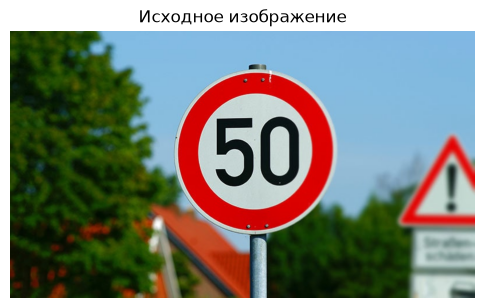

In [25]:
image = cv2.imread('znak.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(image)
plt.axis("off")
plt.title("Исходное изображение")
plt.show()

In [26]:
def show(img1, img2, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(img1)
    axes[0].set_title("До")
    axes[0].axis("off")

    if title:
        axes[1].imshow(img2)
        axes[1].set_title(title)
        axes[1].axis("off")
    else:
        axes[1].imshow(img2)
        axes[1].set_title("После")
        axes[1].axis("off")        
    plt.tight_layout()
    plt.show()

Удобная функция, с помощью которой будет выводиться сразу два изображения, чтобы не дублировать код при каждом изменении 

## Задание 1. Базовые трансформации

### ToGray

Мягкий вариант


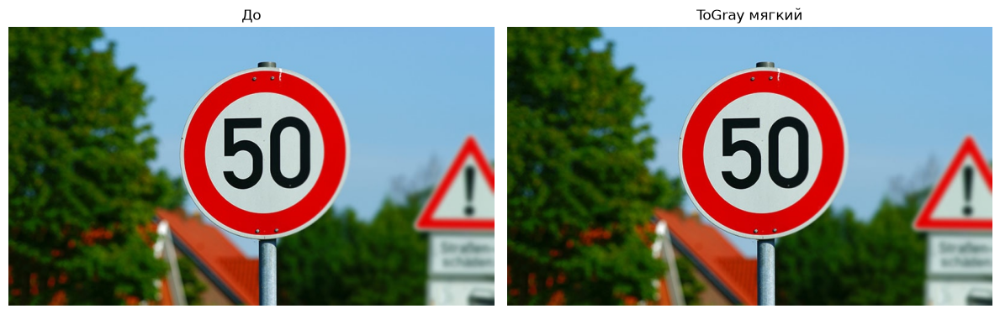

Жёсткий вариант


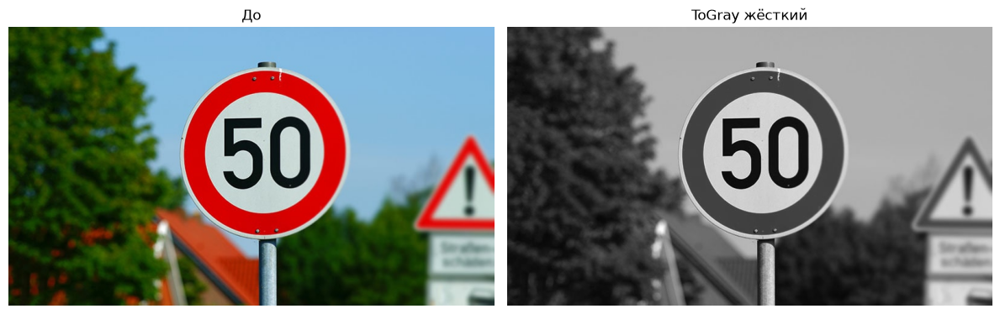

In [27]:
print("Мягкий вариант")
transformation = alb.ToGray(p=0.5)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "ToGray мягкий")

print("Жёсткий вариант")
transformation = alb.ToGray(p=1.0)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "ToGray жёсткий")


ToGray переводит изображение в оттенки серого. Это можно использовать, если цвет не важен для распознавания, но для дорожных знаков такой вариант не самый удачный, потому что цвет помогает отличать знаки. У этой функции нет параметра силы, поэтому отдельного мягкого и жёсткого варианта нет.


### CoarseDropout

Мягкий вариант


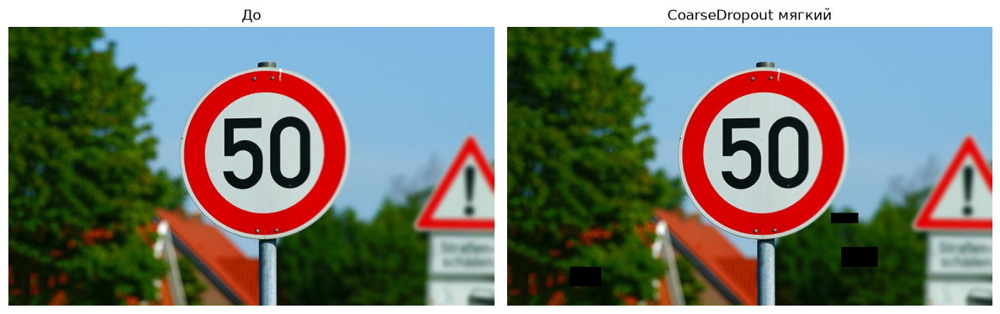

Жёсткий вариант


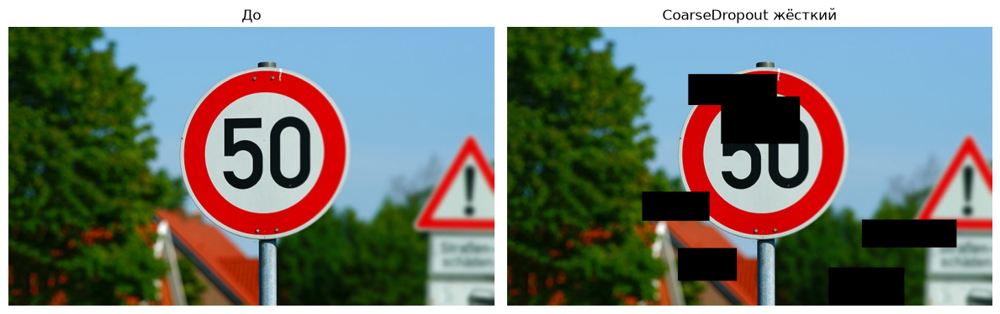

In [28]:
print("Мягкий вариант")
transformation = alb.CoarseDropout(
    num_holes_range=(1, 3),
    hole_height_range=(0.03, 0.08),
    hole_width_range=(0.03, 0.08),
    p=1.0
)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "CoarseDropout мягкий")

print("Жёсткий вариант")
transformation = alb.CoarseDropout(
    num_holes_range=(5, 8),
    hole_height_range=(0.1, 0.2),
    hole_width_range=(0.1, 0.2),
    p=1.0
)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "CoarseDropout жёсткий")


CoarseDropout закрывает случайные участки изображения. В мягком варианте знак ещё хорошо виден, а в жёстком часть цифры или контура может пропасть. Такой способ подходит, чтобы имитировать предметы, которые частично закрывают знак.


### RandomBrightnessContrast

Мягкий вариант


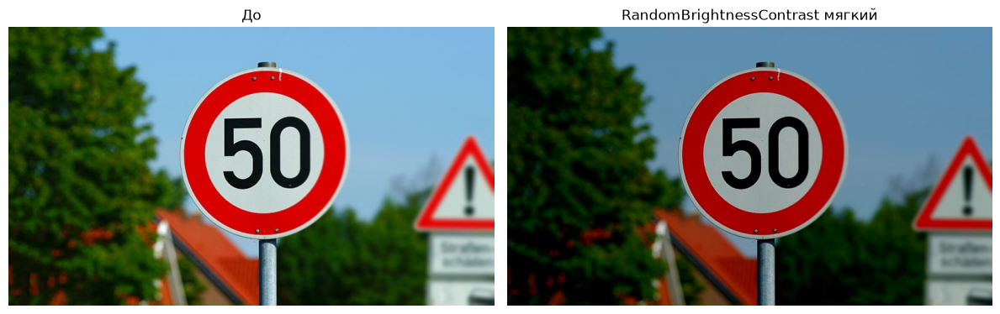

Жёсткий вариант


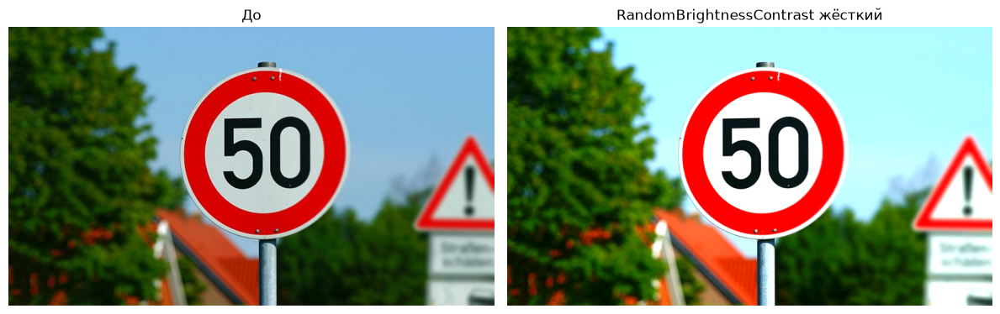

In [29]:
print("Мягкий вариант")
transformation = alb.RandomBrightnessContrast(
    brightness_limit=0.15,
    contrast_limit=0.15,
    p=1.0
)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "RandomBrightnessContrast мягкий")

print("Жёсткий вариант")
transformation = alb.RandomBrightnessContrast(
    brightness_limit=0.45,
    contrast_limit=0.45,
    p=1.0
)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "RandomBrightnessContrast жёсткий")


RandomBrightnessContrast меняет яркость и контраст. Это полезно, когда фотографии сделаны при разном освещении, но слишком сильное изменение мешает разглядеть цифры.


### ShiftScaleRotate

Мягкий вариант


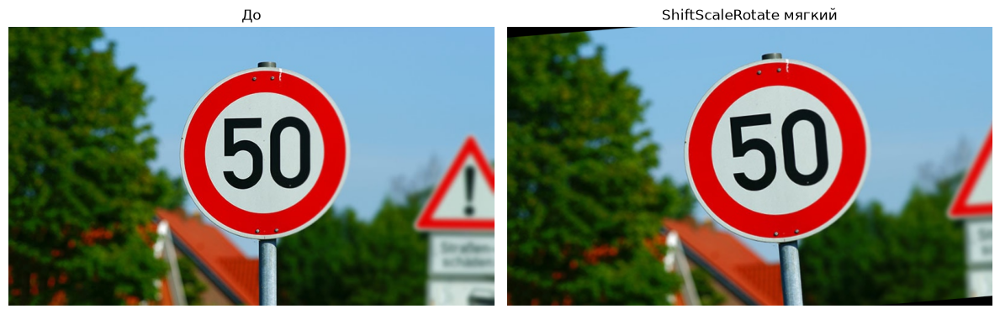

Жёсткий вариант


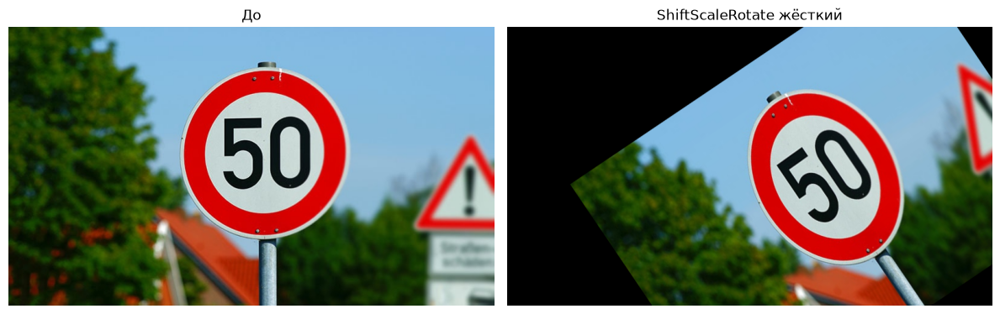

In [30]:
print("Мягкий вариант")
transformation = alb.ShiftScaleRotate(
    shift_limit=0.08,
    scale_limit=0.1,
    rotate_limit=12,
    p=1.0
)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "ShiftScaleRotate мягкий")


print("Жёсткий вариант")
transformation = alb.ShiftScaleRotate(
    shift_limit=0.2,
    scale_limit=0.25,
    rotate_limit=35,
    p=1.0
)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "ShiftScaleRotate жёсткий")


ShiftScaleRotate немного сдвигает, увеличивает или уменьшает и поворачивает изображение. Это помогает показать, что знак может быть снят с разных положений, но большой поворот или сдвиг могут испортить его вид.


### RGBShift

Мягкий вариант


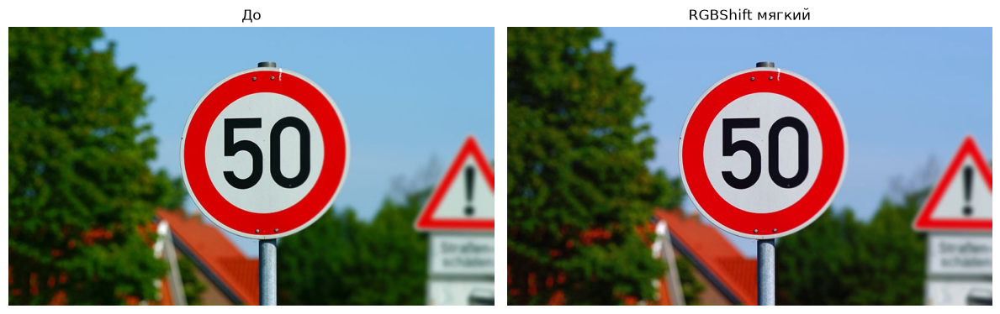

Жёсткий вариант


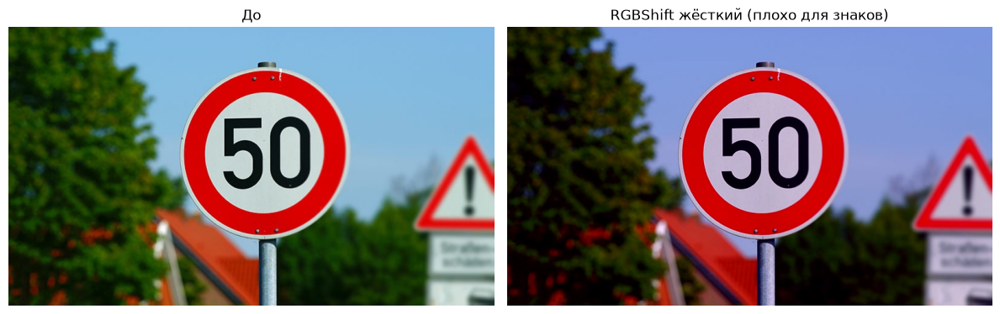

In [43]:
print("Мягкий вариант")
transformation = alb.RGBShift(
    r_shift_limit=12,
    g_shift_limit=12,
    b_shift_limit=12,
    p=1.0
)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "RGBShift мягкий")

print("Жёсткий вариант")
transformation = alb.RGBShift(
    r_shift_limit=50,
    g_shift_limit=50,
    b_shift_limit=50,
    p=1.0
)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "RGBShift жёсткий (плохо для знаков)")


RGBShift отдельно меняет значения красного, зелёного и синего каналов. Небольшое изменение можно использовать для имитации разных камер, а сильное здесь не подходит, потому что цвет знака становится неправильным.


### CLAHE

Мягкий вариант


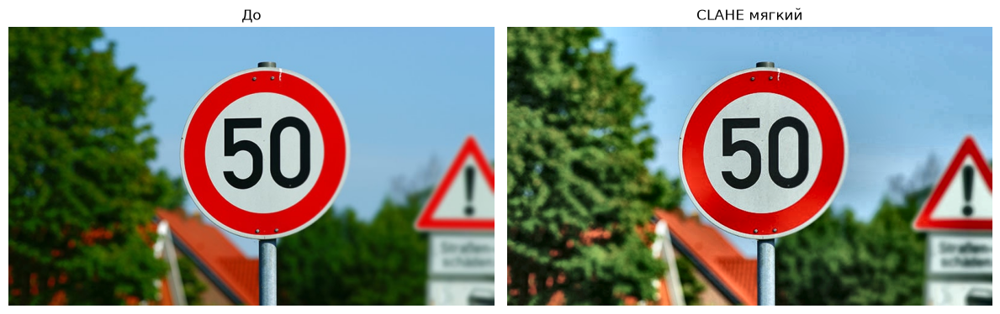

Жёсткий вариант


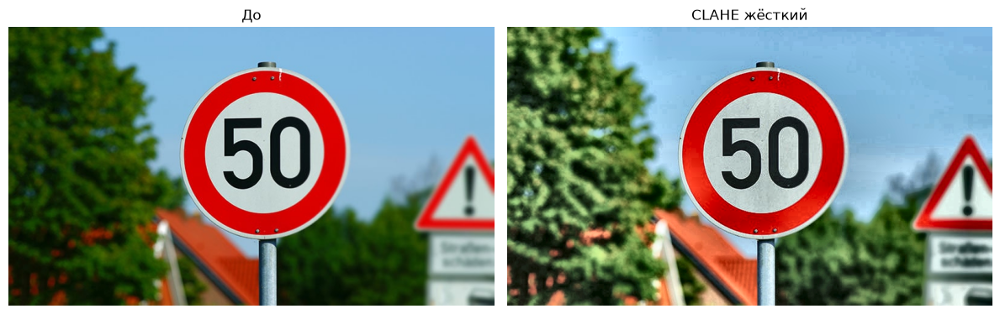

In [44]:
print("Мягкий вариант")
transformation = alb.CLAHE(clip_limit=2.0, p=1.0)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "CLAHE мягкий")


print("Жёсткий вариант")
transformation = alb.CLAHE(clip_limit=6.0, p=1.0)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "CLAHE жёсткий")


CLAHE повышает контраст отдельных участков изображения. Это может помочь, если знак снят при плохом освещении, но при большом clip_limit изображение выглядит слишком резким.


### Perspective

Мягкий вариант


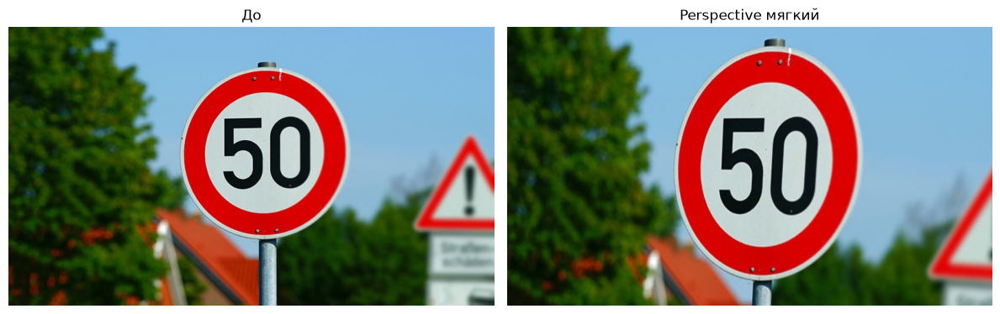

Жёсткий вариант


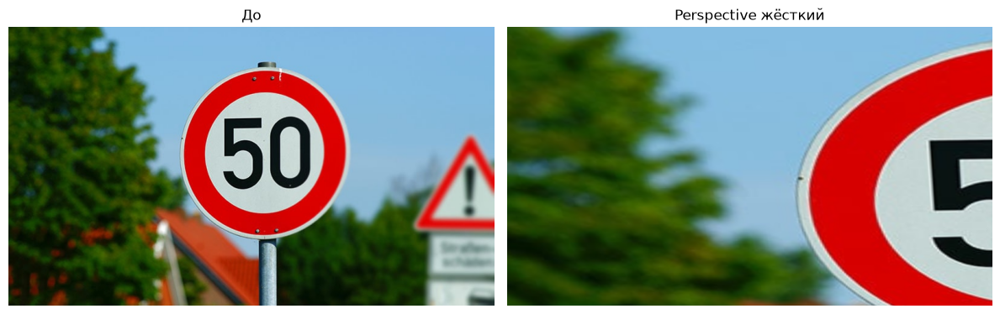

In [46]:
print("Мягкий вариант")
transformation = alb.Perspective(scale=(0.04, 0.09), p=1.0)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "Perspective мягкий")

print("Жёсткий вариант")
transformation = alb.Perspective(scale=(0.15, 0.3), p=1.0)
aug_image = transformation(image=image)["image"]
show(image, aug_image, "Perspective жёсткий")


Perspective меняет перспективу и показывает знак под другим углом. Небольшое искажение подходит для таких фотографий, а слишком сильное может изменить форму знака.


### Таблица

| Трансформация | Основные параметры | Для чего нужна | Что может испортить |
|---|---|---|---|
| ToGray | нет | Переводит изображение в серый цвет | Теряется цвет знака |
| CoarseDropout | `num_holes_range`, `hole_height_range`, `hole_width_range` | Имитирует частичное перекрытие | Может закрыть цифру или контур |
| RandomBrightnessContrast | `brightness_limit`, `contrast_limit` | Имитирует разное освещение | Знак может стать слишком тёмным или светлым |
| ShiftScaleRotate | `shift_limit`, `scale_limit`, `rotate_limit` | Меняет положение, размер и угол | Знак может выйти за границы или сильно повернуться |
| RGBShift | `r_shift_limit`, `g_shift_limit`, `b_shift_limit` | Меняет цвета | Цвет знака может стать неестественным |
| CLAHE | `clip_limit` | Повышает локальный контраст | Могут появиться слишком резкие детали |
| Perspective | `scale` | Имитирует съёмку под углом | Может сильно исказить форму знака |


## Задание 2. Влияние параметров

### RandomBrightnessContrast

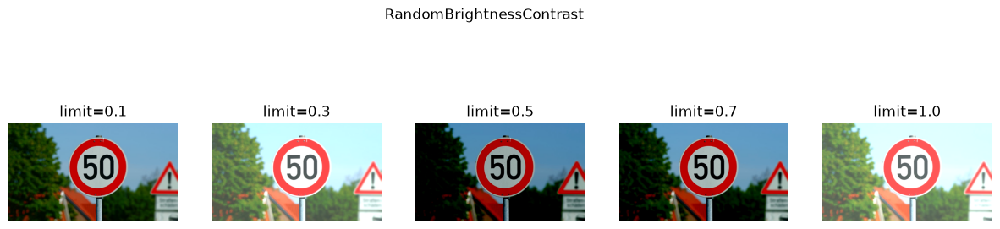

In [34]:
limits = [0.1, 0.3, 0.5, 0.7, 1.0]

plt.figure(figsize=(15, 4))
for i, lim in enumerate(limits):
    transformation = alb.RandomBrightnessContrast(
        brightness_limit=lim,
        contrast_limit=lim,
        p=1.0
    )
    aug_image = transformation(image=image)["image"]
    plt.subplot(1, 5, i+1)
    plt.imshow(aug_image)
    plt.title(f"limit={lim}")
    plt.axis("off")
plt.suptitle("RandomBrightnessContrast")
plt.show()

### ShiftScaleRotate (rotate)

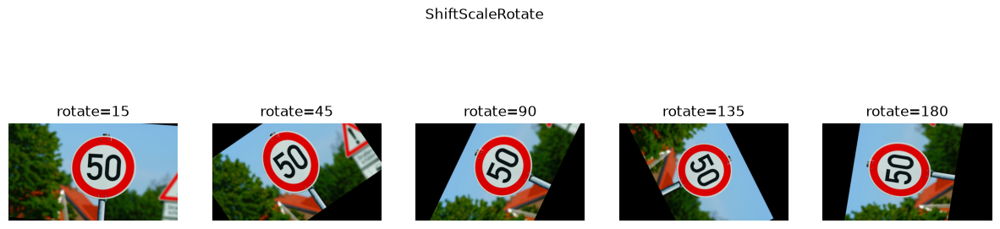

In [35]:
angles = [15, 45, 90, 135, 180]

plt.figure(figsize=(15, 4))
for i, angle in enumerate(angles):
    transformation = alb.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.1,
        rotate_limit=angle,
        p=1.0
    )
    aug_image = transformation(image=image)["image"]
    plt.subplot(1, 5, i+1)
    plt.imshow(aug_image)
    plt.title(f"rotate={angle}")
    plt.axis("off")
plt.suptitle("ShiftScaleRotate")
plt.show()

### CoarseDropout (количество дырок)

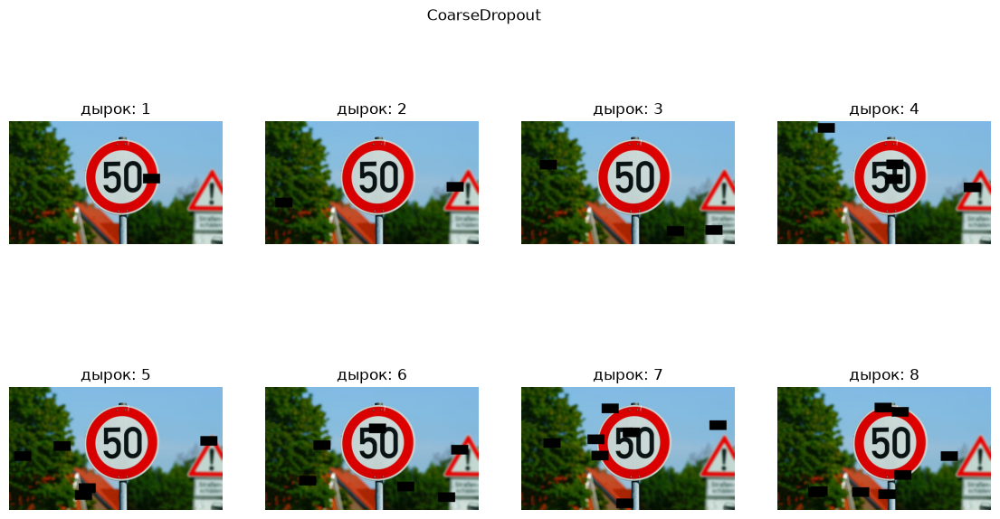

In [36]:
holes = [1, 2, 3, 4, 5, 6, 7, 8]

plt.figure(figsize=(14, 7))
for i, n in enumerate(holes):
    transformation = alb.CoarseDropout(
        num_holes_range=(n, n),
        hole_height_range=(0.08, 0.08),
        hole_width_range=(0.08, 0.08),
        p=1.0
    )
    aug_image = transformation(image=image)["image"]
    plt.subplot(2, 4, i+1)
    plt.imshow(aug_image)
    plt.title(f"дырок: {n}")
    plt.axis("off")
plt.suptitle("CoarseDropout")
plt.show()


### Сетка 3×3

В каждой строке меняется только один параметр: яркость, угол поворота или количество дырок.


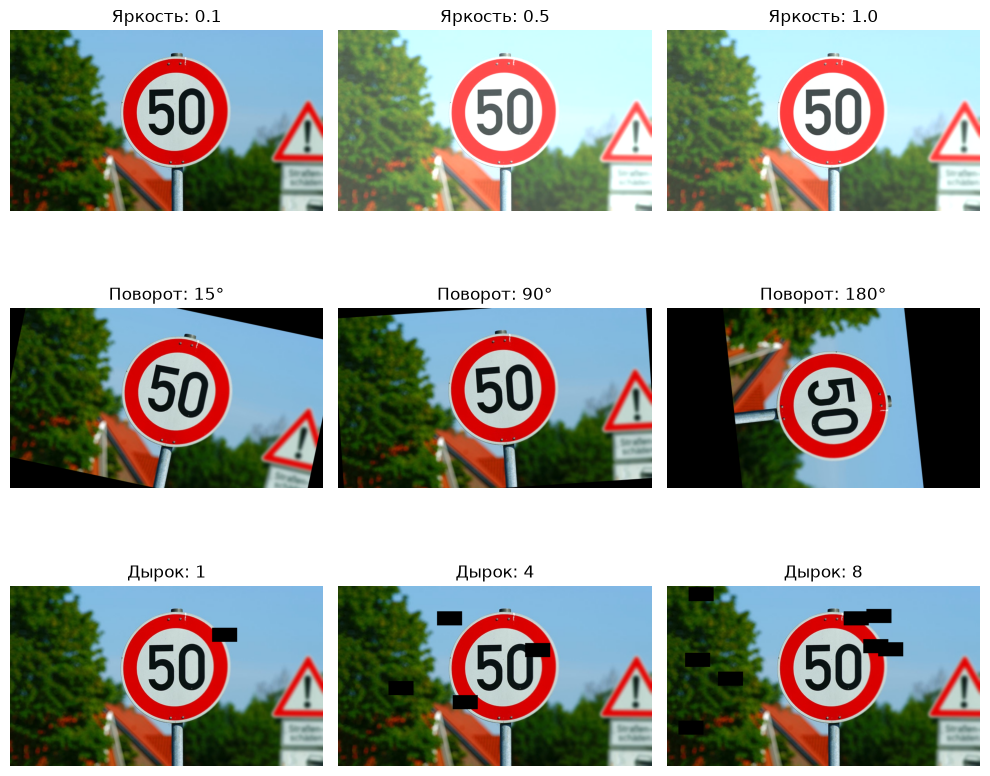

In [37]:
fig, axes = plt.subplots(3, 3, figsize=(10, 9))

brightness = [0.1, 0.5, 1.0]
angles = [15, 90, 180]
hole_counts = [1, 4, 8]

for i, value in enumerate(brightness):
    aug = alb.RandomBrightnessContrast(brightness_limit=value, contrast_limit=0.0, p=1.0)(image=image)["image"]
    axes[0, i].imshow(aug)
    axes[0, i].set_title(f"Яркость: {value}")

for i, value in enumerate(angles):
    aug = alb.ShiftScaleRotate(shift_limit=0.0, scale_limit=0.0, rotate_limit=value, p=1.0)(image=image)["image"]
    axes[1, i].imshow(aug)
    axes[1, i].set_title(f"Поворот: {value}°")

for i, value in enumerate(hole_counts):
    aug = alb.CoarseDropout(num_holes_range=(value, value), hole_height_range=(0.08, 0.08), hole_width_range=(0.08, 0.08), p=1.0)(image=image)["image"]
    axes[2, i].imshow(aug)
    axes[2, i].set_title(f"Дырок: {value}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

При небольшом количестве дырок знак обычно остаётся читаемым, если они не закрывают цифру. Когда дырок становится больше, важные части знака могут пропасть и распознать его сложнее.
При разном повороте и яркости соответственно значение знака читается по разному


## Задание 3. Свой пайплайн

Сценарий: распознавание дорожных знаков.


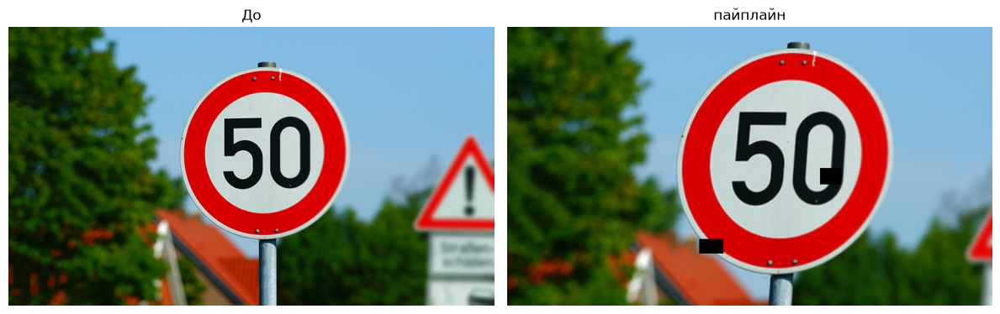

In [54]:
transformation = alb.Compose([
    alb.ShiftScaleRotate(
        shift_limit=0.08,
        scale_limit=0.12,
        rotate_limit=12,
        p=0.65
    ),
    alb.Perspective(scale=(0.04, 0.1), p=0.35),
    alb.RandomBrightnessContrast(
        brightness_limit=0.18,
        contrast_limit=0.18,
        p=0.5
    ),
    alb.CLAHE(clip_limit=2.0, p=0.3),
    alb.CoarseDropout(
        num_holes_range=(1, 3),
        hole_height_range=(0.03, 0.07),
        hole_width_range=(0.03, 0.07),
        p=0.3
    ),
  
],save_applied_params=True)

aug_image = transformation(image=image,save_applied_params=True,)["image"]
show(image, aug_image, "пайплайн")



Поворот и перспектива помогают учесть, что знак могут снять под разным углом. Изменение яркости подходит для фотографий при разном освещении. Сильное изменение цвета не используется, чтобы не менять внешний вид знака. У всех трансформаций вероятность меньше 1.


## Задание 4. Генерация датасета

In [39]:
import csv

if not os.path.exists('dataset'):
    os.mkdir('dataset')

log = []
for i in range(50):
    out = transformation(image=image,save_applied_params=True ) # чит параметр,  спомощью него я сохраню все примененые параметры к картинке
    aug_image = out['image']
    
    name = f'dataset/img_{i}.jpg'
    cv2.imwrite(name, cv2.cvtColor(aug_image, cv2.COLOR_RGB2BGR))
    transform = out['applied_transforms']
    option = str(transform)
    
    log.append({'file': name, 'params': option})

with open('augmentation_log.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=['file', 'params'])
    writer.writeheader()
    writer.writerows(log)

print("Датасет создан и лог сохранен")

Датасет создан и лог сохранен


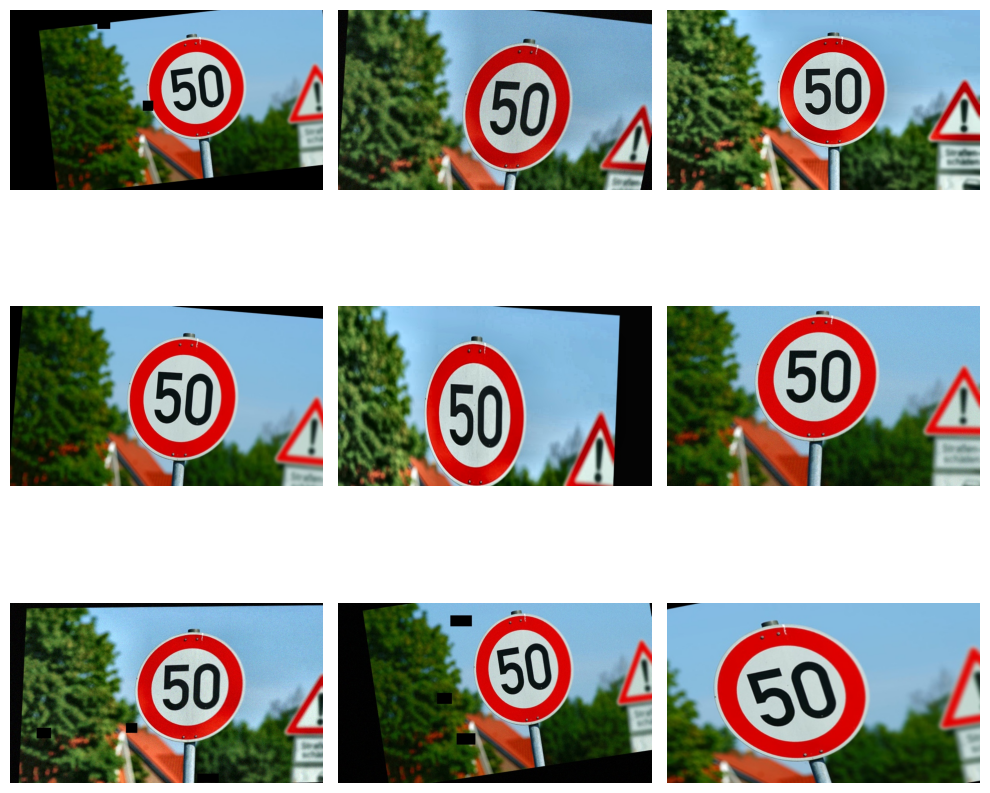

In [40]:
import random


name = [f'dataset/img_{i}.jpg' for i in range(20)]
random.shuffle(name)  # функция рандомного перемешивания массива
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    img = cv2.imread(name[i])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.imshow(img)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Задание 5*. Сравнение пайплайнов

Сравним свой пайплайн с вариантом, в котором изменения сильнее. Посмотрим на среднюю яркость каналов RGB, гистограммы и сами изображения.

Средняя яркость RGB:
Исходное изображение: [103.57 109.83  99.21]
Свой пайплайн: [119.89 115.92 109.65]
Агрессивный пайплайн: [53.58 40.89 77.68]


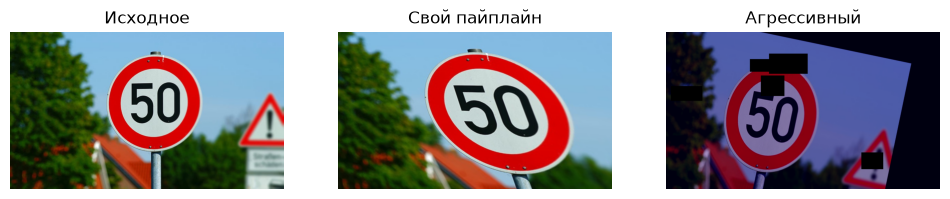

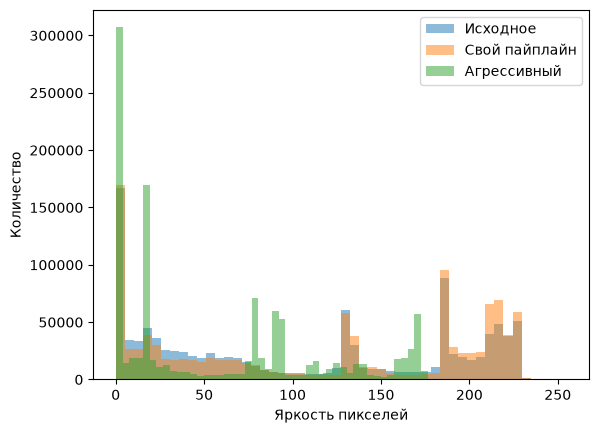

In [51]:
aggressive_transformation == alb.Compose([
    alb.Perspective(
    scale=(0.05, 1.0),
    p=0.3
),
    alb.CLAHE(
    clip_limit=5.0,
    p=0.45
),
    alb.RGBShift(
    r_shift_limit=100,
    g_shift_limit=100,
    b_shift_limit=100,
    p=0.3
),
    alb.ToGray(
    p=0.15
),
    alb.CoarseDropout(
    num_holes_range=(4,8),
    hole_width_range=(0.1, 0.2),
    hole_height_range=(0.1, 0.2),
    p=0.6
),
    alb.ShiftScaleRotate(
    shift_limit=0.2,
    scale_limit=0.2,
    rotate_limit=180,
    p=0.7
),
   alb.RandomBrightnessContrast(
    brightness_limit=0.5,
    contrast_limit=0.5,
    p=0.65
) 
])

my_image = transformation(image=image)["image"]
aggressive_image = aggressive_transformation(image=image)["image"]

print("Средняя яркость RGB:")
print("Исходное изображение:", np.mean(image, axis=(0, 1)).round(2))
print("Свой пайплайн:", np.mean(my_image, axis=(0, 1)).round(2))
print("Агрессивный пайплайн:", np.mean(aggressive_image, axis=(0, 1)).round(2))


plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Исходное")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(my_image)
plt.title("Свой пайплайн")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(aggressive_image)
plt.title("Агрессивный")
plt.axis("off")

plt.show()

plt.hist(image.ravel(), bins=50, alpha=0.5, label="Исходное")
plt.hist(my_image.ravel(), bins=50, alpha=0.5, label="Свой пайплайн")
plt.hist(aggressive_image.ravel(), bins=50, alpha=0.5, label="Агрессивный")
plt.xlabel("Яркость пикселей")
plt.ylabel("Количество")
plt.legend()
plt.show()

По изображениям видно, что свой пайплайн сохраняет знак лучше. Агрессивный вариант сильнее (намного) меняет цвет и закрывает части изображения, поэтому цифру распознать сложнее, а иногда и впринципе увидеть знак на фоне. Значения средней яркости и гистограммы показывают, насколько изменились каналы RGB.

## Задание 6*. Работа с bounding box

Зададим рамку вокруг знака и применим к изображению поворот со сдвигом и обрезку. После преобразования посмотрим, как изменилась рамка.

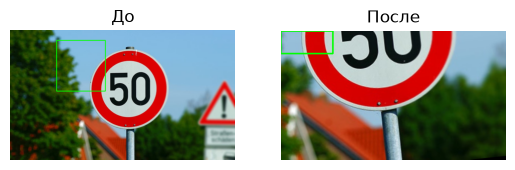

Исходная рамка: [165, 35, 338, 215]
Новая рамка: [0.0, 0.0, 97.10996150970459, 42.13278377056122]


In [55]:
bbox = [165, 35, 338, 215]
class_labels = ["speed_limit_50"]

bbox_transform = alb.Compose([
    alb.ShiftScaleRotate(shift_limit=0.03, scale_limit=0.05, rotate_limit=10, p=1.0),
    alb.RandomCrop(height=240, width=420, p=1.0)
], bbox_params=alb.BboxParams(format="pascal_voc", label_fields=["class_labels"]))

result = bbox_transform(image=image, bboxes=[bbox], class_labels=class_labels)

result_image = result["image"].copy()
original_image = image.copy()

cv2.rectangle(original_image, (165, 35), (338, 215), (0, 255, 0), 2)

new_bbox = result["bboxes"][0]

x1 = int(new_bbox[0])
y1 = int(new_bbox[1])
x2 = int(new_bbox[2])
y2 = int(new_bbox[3])

cv2.rectangle(result_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("До")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_image)
plt.title("После")
plt.axis("off")

plt.show()

print("Исходная рамка:", bbox)
print("Новая рамка:", new_bbox)

После преобразований рамка переместилась вместе со знаком. Если знак полностью попадёт за границу обрезки, рамка может исчезнуть.

## Выводы

В работе были проверены разные способы аугментации изображений. Для дорожных знаков лучше подходят небольшие изменения положения и освещения, потому что сильное изменение цвета или закрытие цифр мешает распознаванию.
